# 03 - Diagnostiquer un modèle : courbes d'apprentissage et taille de batch

Les **courbes d'apprentissage** (perte en fonction des époques, sur le train et la validation) permettent
de reconnaître :

- le **sous-apprentissage** : les deux courbes restent hautes, le modèle n'a pas assez appris ;
- le **sur-apprentissage** : la perte de train continue à baisser alors que celle de validation remonte ;
- un **bon compromis** : les deux courbes descendent puis se stabilisent proches l'une de l'autre ;
- des **échantillons non représentatifs** : un écart important et persistant entre train et validation,
  car les deux jeux ne suivent pas la même distribution.

On étudie ensuite l'effet de la **taille de batch** (descente de gradient par batch, stochastique, mini-batch).

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from velo_utils import load_splits, plot_history, PALETTE

keras.utils.set_random_seed(42)  # reproductibilité
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


In [2]:
X_train, X_test, y_train, y_test = load_splits()
Xtr, Xte = X_train.to_numpy(), X_test.to_numpy()
ytr, yte = y_train.to_numpy(), y_test.to_numpy()
n_features = Xtr.shape[1]
print("train :", Xtr.shape, "| test :", Xte.shape)

train : (585, 33) | test : (146, 33)


In [3]:
def make_model(hidden=(64, 64), optimizer=None, X=None):
    """MLP : Normalization -> couches cachées ReLU -> 1 sortie linéaire."""
    X = Xtr if X is None else X
    norm = layers.Normalization()
    norm.adapt(X)
    model = keras.Sequential([keras.Input(shape=(X.shape[1],)), norm])
    for units in hidden:
        model.add(layers.Dense(units, activation="relu"))
    model.add(layers.Dense(1))
    model.compile(optimizer=optimizer or keras.optimizers.Adam(learning_rate=1e-3), loss="mae")
    return model

## 1. Sous-apprentissage

Un modèle linéaire (aucune couche cachée), entraîné seulement 20 époques avec un petit learning rate :
les courbes descendent encore à la fin, le modèle n'a pas fini d'apprendre.

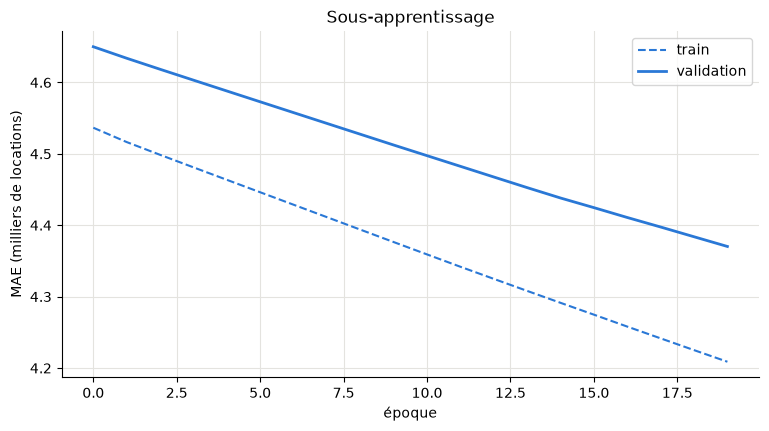

In [4]:
under = make_model(hidden=(), optimizer=keras.optimizers.Adam(learning_rate=1e-3))
h_under = under.fit(Xtr, ytr, epochs=20, validation_split=0.2, verbose=0)
plot_history(h_under, title="Sous-apprentissage"); plt.show()

## 2. Sur-apprentissage

Un très gros réseau (3 × 512 neurones, ~540 000 paramètres) entraîné longtemps sur seulement 100 jours :
il **mémorise** le train (perte proche de 0) tandis que la perte de validation stagne bien au-dessus.

543,300 paramètres pour 100 exemples


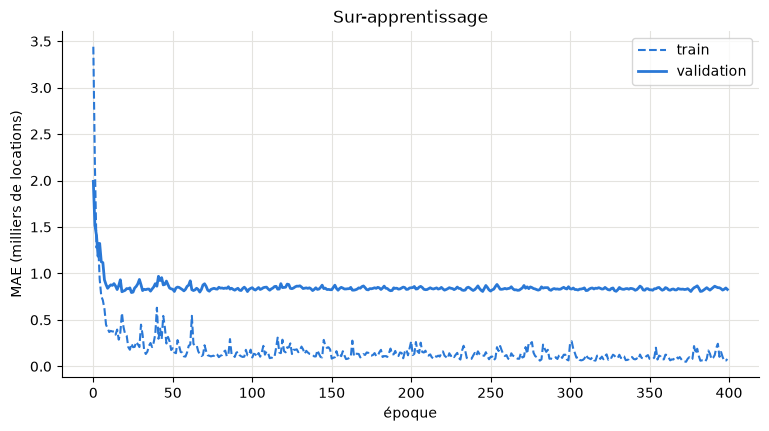

In [5]:
idx = np.random.default_rng(0).choice(len(Xtr), size=100, replace=False)
over = make_model(hidden=(512, 512, 512), X=Xtr[idx])
print(f"{over.count_params():,} paramètres pour {len(idx)} exemples")
h_over = over.fit(Xtr[idx], ytr[idx], epochs=400, validation_data=(Xte, yte), verbose=0)
plot_history(h_over, title="Sur-apprentissage"); plt.show()

## 3. Bon compromis

Un réseau de taille raisonnable (2 × 64) entraîné sur tout le train.

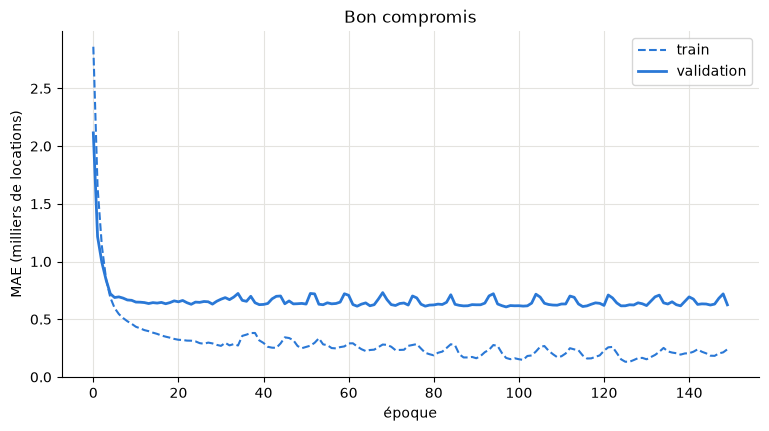

In [6]:
good = make_model(hidden=(64, 64))
h_good = good.fit(Xtr, ytr, epochs=150, validation_split=0.2, verbose=0)
plot_history(h_good, title="Bon compromis"); plt.show()

## 4. Échantillons non représentatifs

On entraîne sur **2011** et on valide sur **2012**. Or les locations ont fortement augmenté en 2012 :
les deux jeux ne viennent pas de la même distribution, et l'écart train / validation ne se résorbe pas.

On retire `yr` (constante dans le train, elle n'apporterait rien et fausserait la normalisation).

Moyenne des locations : 2011 = 3.41k, 2012 = 5.60k


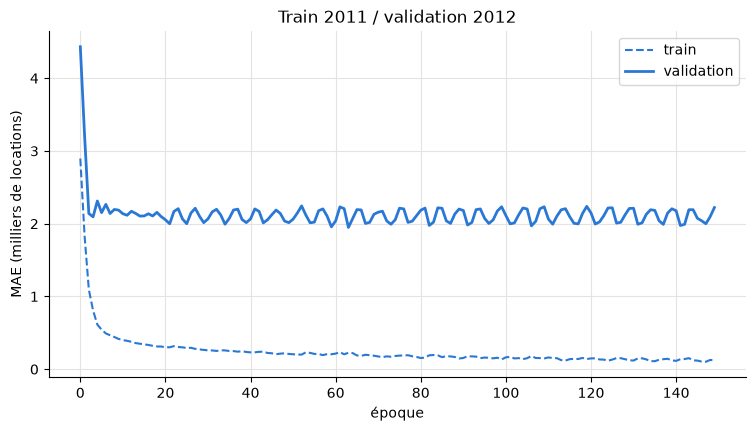

In [7]:
from velo_utils import prepare

data = prepare()
is_2011 = data["yr"] == 0
X_2011 = data[is_2011].drop(columns=["cnt", "yr"]).to_numpy()
y_2011 = data.loc[is_2011, "cnt"].to_numpy()
X_2012 = data[~is_2011].drop(columns=["cnt", "yr"]).to_numpy()
y_2012 = data.loc[~is_2011, "cnt"].to_numpy()
print(f"Moyenne des locations : 2011 = {y_2011.mean():.2f}k, 2012 = {y_2012.mean():.2f}k")

biased = make_model(hidden=(64, 64), X=X_2011)
h_biased = biased.fit(X_2011, y_2011, epochs=150, validation_data=(X_2012, y_2012), verbose=0)
plot_history(h_biased, title="Train 2011 / validation 2012"); plt.show()

C'est pour cela qu'on mélange les données avant de les découper (`df.sample` dans `split()`).

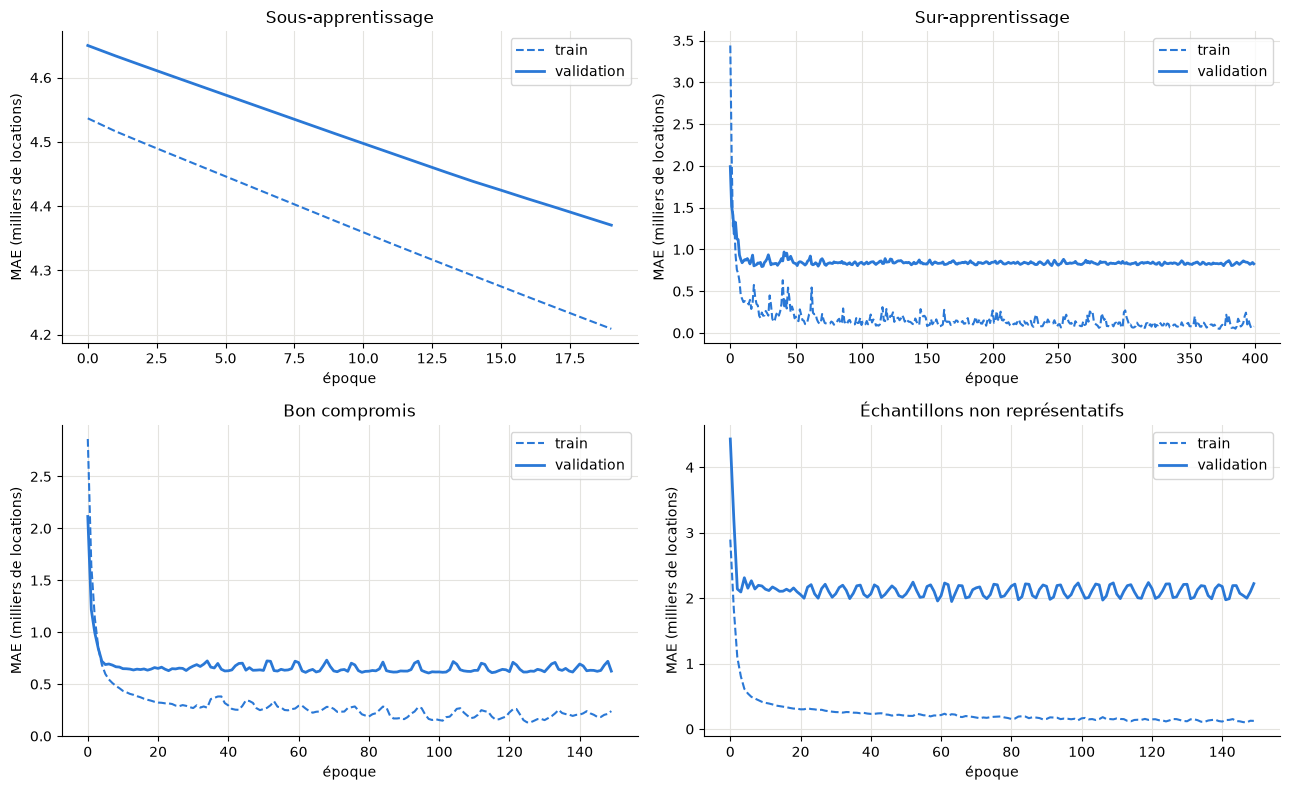

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (title, h) in zip(axes.flat, {
    "Sous-apprentissage": h_under,
    "Sur-apprentissage": h_over,
    "Bon compromis": h_good,
    "Échantillons non représentatifs": h_biased,
}.items()):
    plot_history(h, title=title, ax=ax)
plt.tight_layout()
plt.show()

## 5. Taille de batch

À chaque mise à jour des poids, le gradient est estimé sur un **batch** d'exemples :

| Méthode | `batch_size` | Mises à jour / époque | Comportement |
|---|---|---|---|
| Descente de gradient (batch) | tout le train | 1 | gradient exact, stable, mais très peu de mises à jour |
| Stochastique (SGD) | 1 | ~470 | très bruitée, lente en temps de calcul |
| Mini-batch | 32 (valeur par défaut de Keras) | ~15 | bon compromis |

Pour bien voir l'effet, on utilise l'optimiseur `SGD` « pur » avec le même learning rate et le même nombre d'époques.

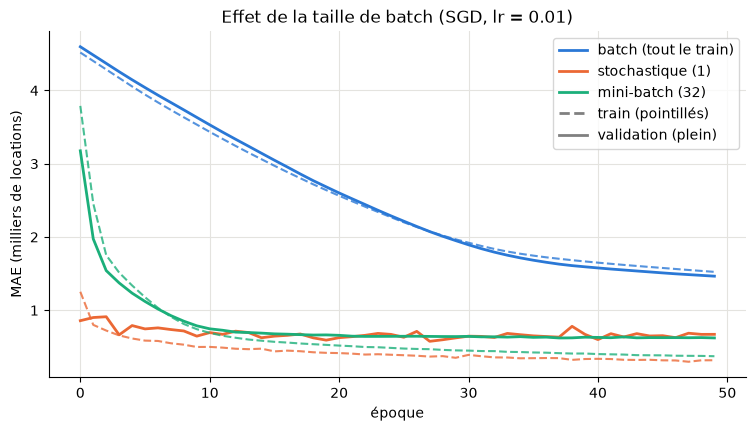

,batch_size,temps (s),MAE val finale,MAE test
méthode,,,,
batch (tout le train),585,7.6,1.465,1.467
stochastique (1),1,48.1,0.671,0.599
mini-batch (32),32,5.7,0.622,0.626


: 

In [ ]:
batch_sizes = {
    "batch (tout le train)": len(Xtr),
    "stochastique (1)": 1,
    "mini-batch (32)": 32,
}
histories, rows = {}, []
for name, bs in batch_sizes.items():
    keras.utils.set_random_seed(42)
    model = make_model(hidden=(64, 64), optimizer=keras.optimizers.SGD(learning_rate=0.01))
    start = time.time()
    histories[name] = model.fit(Xtr, ytr, epochs=50, batch_size=bs, validation_split=0.2, verbose=0)
    rows.append({
        "méthode": name,
        "batch_size": bs,
        "temps (s)": round(time.time() - start, 1),
        "MAE val finale": round(histories[name].history["val_loss"][-1], 3),
        "MAE test": round(model.evaluate(Xte, yte, verbose=0), 3),
    })

plot_history(histories, title="Effet de la taille de batch (SGD, lr = 0.01)"); plt.show()
pd.DataFrame(rows).set_index("méthode")

- **Batch complet** : 50 mises à jour seulement en 50 époques, le modèle a à peine commencé à apprendre.
- **Stochastique** : converge en peu d'époques, mais la courbe est bruitée et chaque époque coûte cher.
- **Mini-batch** : la convergence est rapide et la courbe lisse, pour un temps de calcul raisonnable.

## À vous de jouer

- Testez `batch_size` = 8, 64, 128 : comment évoluent le temps d'entraînement et la MAE ?
- Avec le batch complet, augmentez le learning rate (0.1, 0.5) ou le nombre d'époques : peut-il rattraper le mini-batch ?
- Dans l'expérience de sur-apprentissage, augmentez la taille de l'échantillon (200, 400) : l'écart train / validation diminue-t-il ?